# Cancer RNA-seq analysis and reproduction of Figures S3 and S4


**Two execution modes**

- **`saved_results` (default):** runs immediately from observed analysis tables in the accompanying `inputs/` folder; it rebuilds the robustness classifications and regenerates both figures. No raw-count analysis is claimed in this mode.
- **`raw_counts`:** executes the complete workflow on your 12 tissue `.h5ad` files. Edit the next cell, activate the `cancer_rnaseq` environment with R packages available, then restart the kernel and run all cells.

The accompanying TSV files contain preprocessed input data. 

## How to navigate this notebook

The workflow is **configure → load separate saved tables or validate raw inputs → sample/design QC → M0 → ESTIMATE → M0-matched/M2 and P1 → LOSO/within-study meta-analysis → ComBat-seq → integrate evidence → draw S3/S4 → export provenance**.

For the quickest figure reproduction, leave `MODE = 'saved_results'` and run all cells. For a new raw-count run, configure the AnnData paths and dependencies first. The statistical settings, model definitions, archived results and figure rules have not changed in this readability revision.


## 1 Configuration and dependencies

Unzip the entire package and keep the notebook beside its `inputs/` folder. Start Jupyter in that extracted folder, or edit `INPUT_DIR`.

For figure reproduction: Python with `numpy`, `pandas`, `scipy`, `matplotlib`, `seaborn`, and `IPython`.

For the raw-count run, additionally install `anndata`, `h5py`, `scikit-learn`, and **`pydeseq2==0.5.4`** in the analysis environment. Rscript must see **`estimate`** and **`sva`**. Installation is separate from scientific execution; the notebook does not install packages automatically. Example Python command in your terminal:

```bash
conda activate cancer_rnaseq
python -m pip install 'pydeseq2==0.5.4' anndata h5py scikit-learn numpy pandas scipy matplotlib seaborn ipython jupyter
jupyter lab
```

Load your R module before launching Jupyter, or set `R_SCRIPT` to its absolute executable. File mapping is explicit; cancer labels may be `Uterine cancer`, `Ovarian cancer`, etc. No literal label `Cancer` is assumed in the inputs.

In [1]:
from pathlib import Path
import json, hashlib, platform, sys, warnings, subprocess, shutil
import importlib.metadata as ilm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import norm, chi2
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from IPython.display import display, Markdown, Image

# Start with saved results to reproduce figures without the large raw AnnData files.
# Set MODE='raw_counts' for the complete analysis, then Restart Kernel and Run All.
MODE = 'saved_results'               # 'saved_results' or 'raw_counts'
INPUT_DIR = Path('./inputs')         # Separate archived TSV result tables
DATA_DIR = Path('./data')
OUTPUT_DIR = Path('./cancer_rnaseq_reproduced')
LAYER = '_.raw'                       # Frozen representation used in the final cancer analysis
N_CPUS = 8
R_SCRIPT = None                       # Full Rscript path, or None to resolve from PATH
TISSUES = ['Bladder','Brain','Breast','Colorectal','Esophagus','Kidney',
           'Liver','Lung','Ovary','Prostate','Skin','Uterus']
H5AD_FILES = {t: DATA_DIR / (t.lower()+'.h5ad') for t in TISSUES}
CONDITION_COL, BATCH_COL, HEALTHY = 'Disease', 'sra_study_acc', 'Healthy'
# Set an explicit disease label per tissue if a file contains multiple diseases.
CANCER_LABELS = {}
TARGET_GENES = sorted(set(['PANX1','PANX2','PANX3','GJC3','GJA1','GJA10','GJA3',
    'GJA4','GJA5','GJA8','GJA9','GJB1','GJB2','GJB3','GJB4','GJB5','GJB6','GJB7',
    'GJC1','GJC2','GJD2','GJD3','GJD4','GJE1']+[f'CALHM{i}' for i in range(1,7)]))
FIGURE_GENES = ['GJA8','GJB2','GJB6','GJA3','PANX2','GJB3','GJB4','GJB5','GJA1',
    'GJC1','CALHM3','GJB7','GJA9','CALHM5','GJA5','GJB1','GJA4','GJC2','GJC3',
    'CALHM6','GJE1','PANX1','CALHM2','GJD3','CALHM1','CALHM4','GJD2','PANX3']
FIGURE_TISSUES = ['Esophagus','Colorectal','Lung','Ovary','Kidney','Brain',
                 'Uterus','Bladder','Breast','Liver','Prostate','Skin']
ALPHA, MIN_COUNT, MIN_SAMPLES, MIN_GROUP = 0.05, 10, 3, 3
MIN_WITHIN = 3
MIN_PURITY_TUMORS, MIN_COMPOSITION_FRACTION, MAX_SCORE_CORR = 10, 0.80, 0.90
QC_LIBRARY_FLOOR, QC_DETECTED_FLOOR, QC_IQR_MULTIPLIER = 100_000, 1_000, 3
# Flags are reported, not automatically removed. Only all-zero libraries are auto-excluded.
EXCLUDE_SAMPLES = {t: [] for t in TISSUES}  # Reviewed IDs, separately within each tissue
RUN_COMPOSITION, RUN_LOSO, RUN_WITHIN, RUN_COMBAT = True, True, True, True
RUN_MIXED_ONLY, RUN_BALANCED = False, False  # Additional optional sensitivities, absent from original figures
BALANCED_ITERATIONS, RNG_SEED = 100, 606
# 'recluster' draws genuine newly calculated dendrograms. 'uploaded_order' preserves
# the uploaded order but omits dendrograms whose historical linkage was not recovered.
EXPRESSION_LAYOUT = 'recluster'
# Legacy figure labels are descriptive cross-method concordance, not independent validation.
CLASSIFICATION_MODE = 'historical'       # Or 'require_two_studies' for a stricter separate export
RESUME_IDENTICAL_FITS = True             # Cached only when full counts/design/software hashes agree
assert MODE in {'saved_results','raw_counts'}
assert len(TARGET_GENES) == 30
for folder in ['QC','DE','ESTIMATE','robustness','figures','tables','cache','provenance']:
    (OUTPUT_DIR/folder).mkdir(parents=True, exist_ok=True)

def write_tsv(df, path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    df.to_csv(path,sep='\t',index=False,na_rep='NA')

def save_figure(fig, name):
    for ext in ['png','pdf']:
        fig.savefig(OUTPUT_DIR/'figures'/f'{name}.{ext}', dpi=300,bbox_inches='tight')

print('Mode:', MODE, '| Counts:', LAYER, '| Tissues:',len(TISSUES),'| Targets:',len(TARGET_GENES))
print('Output:',OUTPUT_DIR.resolve())


Mode: saved_results | Counts: _.raw | Tissues: 12 | Targets: 30
Output: /workspace/scratch/e4c94c26dd9e/deliverables/Cancer_RNAseq_S3_S4/cancer_rnaseq_reproduced


## 2 Separate input tables and provenance

The separate TSV tables were recovered from `RNAseq_Figure_Reproduction_Code.zip` and the saved integrated, LOSO, within-study, and meta-analysis TSV files. Core implementation was recovered from `RNAseq_Full_Pipeline_Code.zip` → `RNAseq_full_pipeline_corrected.ipynb`. Hashes identify the precise table bytes.

The 30-gene analysis includes GJA10 and GJD4; the uploaded 28-row heatmaps omit these two unestimated targets. The full analysis/audit still retains them. Gallbladder and gastrointestinal soft tissue remain outside the agreed 12-tissue scope.

The next code cell loads these six ordinary TSV files using `pd.read_csv`. You can inspect them directly in a text editor or spreadsheet application. `input_manifest.json` records their original checksums; the notebook reports accidental changes before analysis.

In [2]:
# Saved results are ordinary, separate TSV files in the inputs folder.
manifest_path = INPUT_DIR / 'input_manifest.json'
if not manifest_path.is_file():
    raise FileNotFoundError(
        f'Missing {manifest_path}. Unzip the complete package and start Jupyter in its folder, '
        'or set INPUT_DIR to the extracted inputs folder.'
    )
SAVED_MANIFEST = json.loads(manifest_path.read_text())
SAVED_TABLES = {}
for name, info in SAVED_MANIFEST.items():
    path = INPUT_DIR / name
    if not path.is_file():
        raise FileNotFoundError(f'Missing saved table: {path}')
    observed_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    if observed_hash != info['sha256']:
        raise ValueError(f'{name} differs from the archived input. Review changes and update its manifest hash if intentional.')
    SAVED_TABLES[name] = pd.read_csv(path, sep='\t')
print('Loaded saved tables:', {name: len(df) for name, df in SAVED_TABLES.items()})


Loaded saved tables: {'target_gene_complete_summary_all_tissues.tsv': 272, 'study_robustness_classification.tsv': 169, 'target_gene_integrated_with_ComBatSeq.tsv': 272, 'LOSO_target_summary_all_tissues.tsv': 272, 'within_study_target_effects_all_tissues.tsv': 1188, 'target_meta_analysis_all_tissues.tsv': 258}


## 3 QC and model fitting functions

**Checkpoints before inference:** unique sample/feature IDs; exact metadata alignment; explicit Healthy and one cancer label; no missing study IDs; finite nonnegative integer counts; library depth and detected-gene QC; Study × Disease tables before and after exclusions; full design rank and positive residual degrees of freedom.

Depth and complexity thresholds are `max(absolute floor, Q1 − 3 × IQR)` within each tissue. These are **flags for review**, not automatic exclusions. The only automatic sample removal is a zero-count library. Reviewed exclusions go in `EXCLUDE_SAMPLES`. Assigned gene counts are not synonymous with sequenced reads or fragments.

The historical gene filter is retained: count ≥10 in at least three samples, recalculated in each analysis cohort. Size-factor normalization and negative-binomial fitting are performed by PyDESeq2 on the full filtered transcriptome. Target-only fitting is never used. PCA/correlation use diagnostic log2 CPM; those values are never substituted for raw counts in DE.

Every fit checks a numeric design matrix and uses an explicit numeric contrast. This makes the cancer direction unambiguous and implements P1 as a **continuous** one-SD purity effect. DESeq2 p-values retain Cook’s filtering and independent filtering; BH-adjusted values are calculated across the tested transcriptome within each model, before target extraction. No log-fold-change shrinkage is applied to the coefficients used in meta-analysis.

### Environment checks and input provenance

These utilities record software and input fingerprints, and check that the raw-analysis dependencies are available. In saved-results mode no R or PyDESeq2 installation is needed. **Output:** software records and, for a raw run, `provenance/R_session.txt`. A failed dependency check stops raw execution before long model fits begin.


In [3]:
def software_versions():
    """Record the actual Python and scientific-package versions for the run manifest."""
    names = ['numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn', 'anndata', 'pydeseq2', 'h5py']
    out = {'python': sys.version, 'platform': platform.platform()}
    for name in names:
        try:
            out[name] = ilm.version(name)
        except ilm.PackageNotFoundError:
            out[name] = 'not installed'
    return out

def sha_file(path):
    """Compute a SHA-256 fingerprint without loading a large input file into memory."""
    # Cache identity includes the actual count and model-matrix bytes.
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def require_raw_environment():
    """Check the Python versioned API and required R packages before any expensive raw-data fitting."""
    import anndata
    import pydeseq2
    if ilm.version('pydeseq2') != '0.5.4':
        raise RuntimeError('For the historical API use pydeseq2==0.5.4; review compatibility before changing it.')
    path = R_SCRIPT or shutil.which('Rscript')
    if (RUN_COMPOSITION or RUN_COMBAT) and (not path):
        raise FileNotFoundError('Rscript required for ESTIMATE/ComBat-seq. Set R_SCRIPT or load the R module.')
    if path:
        wanted = (['estimate'] if RUN_COMPOSITION else []) + (['sva'] if RUN_COMBAT else [])
        r = 'p <- c(' + ','.join((json.dumps(p) for p in wanted)) + '); ' + 'for (x in p) {if(!requireNamespace(x,quietly=TRUE)) stop(paste("Missing R package",x)); ' + 'cat(x,as.character(packageVersion(x)),"\\n")}; sessionInfo()'
        proc = subprocess.run([str(path), '-e', r], capture_output=True, text=True)
        (OUTPUT_DIR / 'provenance/R_session.txt').write_text(proc.stdout + '\n' + proc.stderr)
        if proc.returncode:
            raise RuntimeError('R dependency probe failed: ' + proc.stderr)
    return path


### Study composition and identifiable model designs

The input is sample metadata aligned to count-matrix rows. Study dummy variables absorb systematic study differences; a binary cancer column defines Cancer minus Healthy. Immune/stromal or purity covariates are added only when the corresponding model requests them. **Checkpoint:** the matrix must have full column rank and positive residual degrees of freedom. Complete Study × Disease confounding cannot be corrected by fitting or ComBat-seq.


In [4]:
def study_table(md):
    """Count Healthy and Cancer samples within each SRA study. Empty groups remain explicit zeros."""
    return pd.crosstab(md[BATCH_COL], md['condition']).reindex(columns=['Healthy', 'Cancer'], fill_value=0)

def design_matrix(md, continuous=(), condition=True, study=True):
    """Build an aligned numeric design with an intercept, study indicators and requested predictors.
The cancer indicator is 1 for Cancer and 0 for Healthy, fixing the coefficient direction."""
    if not md.index.is_unique:
        raise ValueError('Duplicate sample IDs')
    X = pd.DataFrame({'Intercept': np.ones(len(md))}, index=md.index)
    if study:
        if BATCH_COL not in md or md[BATCH_COL].isna().any():
            raise ValueError('Missing study metadata')
        levels = sorted(md[BATCH_COL].astype(str).unique())
        for s in levels[1:]:
            X['Study[' + s + ']'] = md[BATCH_COL].astype(str).eq(s).astype(float)
    for c in continuous:
        v = pd.to_numeric(md[c], errors='raise').astype(float)
        if not np.isfinite(v).all():
            raise ValueError('Nonfinite covariate ' + c)
        X[c] = v
    if condition:
        if set(md['condition']) != {'Healthy', 'Cancer'}:
            raise ValueError('Both conditions are required')
        if md['condition'].value_counts().min() < MIN_GROUP:
            raise ValueError('Insufficient replication per condition')
        X['Cancer_vs_Healthy'] = md['condition'].eq('Cancer').astype(float)
    if not len(X):
        raise ValueError('Empty cohort')
    return X.astype(float)

def check_design(X, outfile=None):
    """Save model-rank diagnostics, then reject non-identifiable models or models without residual degrees of freedom."""
    rank = int(np.linalg.matrix_rank(X.to_numpy()))
    info = {'n_samples': len(X), 'n_coefficients': X.shape[1], 'rank': rank, 'residual_df': len(X) - rank, 'condition_number': float(np.linalg.cond(X)), 'full_rank': rank == X.shape[1]}
    if outfile:
        write_tsv(pd.DataFrame([info]), outfile)
    if not info['full_rank']:
        raise ValueError('Rank deficient design: disease/covariates not separable from study')
    if info['residual_df'] <= 0:
        raise ValueError('No residual degrees of freedom')
    return info


### Filter low-count genes within each model cohort

For each primary, subset, or study-specific fit, keep genes with at least 10 assigned counts in at least three samples. This reproduces the historical filter. **Output:** a sample-by-gene integer-count matrix. Filtering precedes normalization and model fitting; the full retained transcriptome supplies dispersion estimation and DE FDR correction.


In [5]:
def low_count_filter(counts):
    """Retain genes with count at least MIN_COUNT in at least MIN_SAMPLES samples in this model cohort."""
    keep = (counts >= MIN_COUNT).sum(axis=0) >= MIN_SAMPLES
    if not keep.any():
        raise ValueError('No genes passed low-count filtering')
    return counts.loc[:, keep]


### Load one tissue and apply sample QC

Read the configured `.h5ad` layer, validate integer counts, sample uniqueness, gene mappings and study labels, then flag low depth and low complexity. Only zero-count libraries and explicitly reviewed exclusions are removed. **Outputs:** retained counts, aligned metadata, gene-symbol mapping, cancer label, sample-QC tables and input hashes. **Checkpoint:** recalculate Study × Disease composition and design rank after exclusions.


In [6]:
def load_and_qc(tissue):
    """Load one tissue, validate counts and annotations, flag depth/complexity problems and apply reviewed exclusions.
Return retained counts, aligned metadata, gene mapping and the original cancer label."""
    import anndata as ad
    path = H5AD_FILES[tissue]
    a = ad.read_h5ad(path)
    if LAYER not in a.layers:
        raise KeyError(f'{path}: required layer {LAYER}; present: {list(a.layers)}')
    if not a.obs_names.is_unique or not a.var_names.is_unique:
        raise ValueError('Duplicate AnnData sample/feature IDs')
    for c in [CONDITION_COL, BATCH_COL]:
        if c not in a.obs:
            raise KeyError('Missing obs column ' + c)
    md = a.obs.copy()
    md.index = md.index.astype(str)
    invalid = md[[CONDITION_COL, BATCH_COL]].isna().any(axis=1)
    invalid |= md[[CONDITION_COL, BATCH_COL]].astype(str).apply(lambda s: s.str.strip().eq('')).any(axis=1)
    if invalid.any():
        raise ValueError(f'{tissue}: {int(invalid.sum())} missing condition/study values; resolve metadata')
    labels = md[CONDITION_COL].astype(str)
    others = sorted(set(labels) - {HEALTHY})
    cancer = CANCER_LABELS.get(tissue)
    if cancer is None:
        if HEALTHY not in set(labels) or len(others) != 1:
            raise ValueError(f'Ambiguous disease labels: {set(labels)}')
        cancer = others[0]
    if cancer not in set(labels) or HEALTHY not in set(labels):
        raise ValueError('Configured contrast absent')
    keep = labels.isin([HEALTHY, cancer])
    a = a[keep.to_numpy()].copy()
    md = md.loc[keep].copy()
    md['condition'] = np.where(md[CONDITION_COL].eq(HEALTHY), 'Healthy', 'Cancer')
    md[BATCH_COL] = md[BATCH_COL].astype(str)
    raw = a.layers[LAYER]
    data = raw.data if sparse.issparse(raw) else np.asarray(raw)
    if not np.isfinite(data).all() or (data < 0).any():
        raise ValueError('Invalid nonfinite/negative counts')
    if not np.allclose(data, np.rint(data), rtol=0, atol=1e-08):
        raise ValueError('Noninteger raw counts; no automatic rounding')
    ids = a.var['gene_id'].astype(str).to_numpy() if 'gene_id' in a.var else a.var_names.astype(str).to_numpy()
    symbols = a.var['gene_name'].astype(str).to_numpy() if 'gene_name' in a.var else ids
    if pd.Index(ids).has_duplicates:
        raise ValueError('Duplicate gene_id annotations')
    gm = pd.DataFrame({'gene_id': ids, 'gene_name': symbols})
    dup = gm.loc[gm.gene_name.isin(TARGET_GENES), 'gene_name'].duplicated(keep=False)
    if dup.any():
        raise ValueError('Multiple gene IDs per target symbol; resolve mapping before analysis')
    arr = raw.toarray() if sparse.issparse(raw) else np.asarray(raw)
    ct = pd.DataFrame(np.rint(arr).astype(np.int64), index=md.index, columns=ids)
    qc = pd.DataFrame({'sample_id': ct.index, 'Study': md[BATCH_COL], 'condition': md['condition'], 'library_size': ct.sum(axis=1), 'detected_genes': (ct >= 1).sum(axis=1)})
    thresholds = {}
    for metric, floor in [('library_size', QC_LIBRARY_FLOOR), ('detected_genes', QC_DETECTED_FLOOR)]:
        q1, q3 = qc[metric].quantile([0.25, 0.75])
        cut = max(floor, q1 - QC_IQR_MULTIPLIER * (q3 - q1))
        thresholds[metric + '_cutoff'] = float(cut)
        qc['low_' + metric] = qc[metric] < cut
    reviewed = set(EXCLUDE_SAMPLES.get(tissue, []))
    if reviewed - set(ct.index):
        raise ValueError('Exclusion list contains unknown sample IDs')
    qc['flag'] = qc.low_library_size | qc.low_detected_genes
    qc['excluded'] = qc.library_size.eq(0) | qc.sample_id.isin(reviewed)
    qc['action'] = np.select([qc.excluded, qc.flag], ['Remove', 'Inspect retained'], default='Keep')
    write_tsv(qc.reset_index(drop=True), OUTPUT_DIR / 'QC' / f'{tissue}_sample_QC.tsv')
    write_tsv(pd.DataFrame([thresholds]), OUTPUT_DIR / 'QC' / f'{tissue}_thresholds.tsv')
    write_tsv(study_table(md).reset_index(), OUTPUT_DIR / 'QC' / f'{tissue}_study_condition_before_QC.tsv')
    retained = qc.loc[~qc.excluded, 'sample_id']
    ct = ct.loc[retained]
    md = md.loc[retained]
    write_tsv(study_table(md).reset_index(), OUTPUT_DIR / 'QC' / f'{tissue}_study_condition_after_QC.tsv')
    X = design_matrix(md)
    check_design(X, OUTPUT_DIR / 'QC' / f'{tissue}_M0_design_QC.tsv')
    sample_plots(tissue, ct, md, qc)
    write_tsv(gm, OUTPUT_DIR / 'QC' / f'{tissue}_gene_map.tsv')
    input_info = {'tissue': tissue, 'file': str(path.resolve()), 'sha256': sha_file(path), 'layer': LAYER, 'n_samples_retained': len(ct), 'n_features': ct.shape[1], 'cancer_label': cancer}
    (OUTPUT_DIR / 'provenance' / f'{tissue}_input.json').write_text(json.dumps(input_info, indent=2))
    return (ct, md, gm, cancer)


### Inspect library properties and global expression structure

Visualize library size, detected genes and the distribution of samples across studies. Diagnostic log2 CPM is used for PCA and sample correlations. **Outputs:** per-tissue QC PNG/PDF plots and PCA coordinates. Inspect isolated samples and strong study separation; these plots do not automatically select exclusions or prove that the cancer effect is identifiable.


In [7]:
def sample_plots(tissue, ct, md, qc):
    """Save diagnostic depth, complexity, study composition, PCA and sample-correlation plots for one tissue.
The log2 CPM transformation is diagnostic only and is never passed to differential-expression fitting."""
    import seaborn as sns
    from sklearn.decomposition import PCA
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, metric in zip(axes[:2], ['library_size', 'detected_genes']):
        sns.boxplot(data=qc, x='condition', y=metric, ax=ax, color='lightgrey')
        sns.stripplot(data=qc, x='condition', y=metric, hue='Study', ax=ax, size=3, alpha=0.5, legend=False)
        ax.set_title(metric)
    tab = study_table(md)
    tab.plot.bar(stacked=True, ax=axes[2], legend=True)
    axes[2].set_title('Study × condition after QC')
    fig.suptitle(tissue)
    fig.tight_layout()
    save_figure(fig, tissue + '_01_sample_and_design_QC')
    plt.close(fig)
    log = np.log2(ct.div(ct.sum(axis=1), axis=0) * 1000000.0 + 1)
    varying = log.var().sort_values(ascending=False).head(min(2000, ct.shape[1])).index
    xy = PCA(n_components=2).fit_transform(log[varying])
    p = pd.DataFrame(xy, index=md.index, columns=['PC1', 'PC2']).join(md)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, key in zip(axes[:2], ['condition', BATCH_COL]):
        sns.scatterplot(data=p, x='PC1', y='PC2', hue=key, ax=ax, legend=key == 'condition')
        ax.set_title('PCA by ' + key)
    im = axes[2].imshow(np.corrcoef(log), vmin=0, vmax=1, cmap='viridis', aspect='auto')
    axes[2].set_title('Sample Pearson correlation log2 CPM')
    fig.colorbar(im, ax=axes[2])
    fig.suptitle(tissue)
    fig.tight_layout()
    save_figure(fig, tissue + '_02_PCA_correlation')
    plt.close(fig)
    write_tsv(p.reset_index(names='sample_id'), OUTPUT_DIR / 'QC' / f'{tissue}_PCA.tsv')


### Fit differential expression and inspect the model

PyDESeq2 estimates size factors, dispersions and regression coefficients from the original integer counts. A numeric contrast tests the intended cancer or continuous-purity coefficient. **Outputs:** all-gene DE tables, an input-validated cache, p-value histograms, volcano and MA plots, plus available fit diagnostics. **Checkpoint:** assess dispersion, outliers and unavailable p-values before interpreting FDR. The cache stores results, not biological evidence from a changed input.


In [8]:
def fit_model(ct, md, gm, X, coefficient, tissue, label, diagnostics=False):
    """Fit the complete filtered transcriptome with PyDESeq2 and test one numeric design coefficient.
Reuse a cache only when counts, sample/gene order, design, contrast and package-version fingerprints match."""
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    from pydeseq2.default_inference import DefaultInference
    if not ct.index.equals(md.index) or not X.index.equals(ct.index):
        raise ValueError('Sample order mismatch')
    check_design(X, OUTPUT_DIR / 'QC' / f'{tissue}_{label}_design_QC.tsv')
    if coefficient not in X:
        raise KeyError(coefficient)
    # Cache identity includes the actual count and model-matrix bytes.
    h = hashlib.sha256(ct.to_numpy().tobytes() + X.to_numpy().tobytes())
    h.update(json.dumps([ct.index.tolist(), ct.columns.tolist(), X.columns.tolist(), coefficient, ALPHA, ilm.version('pydeseq2')]).encode())
    key = h.hexdigest()
    cache = OUTPUT_DIR / 'cache' / f'{tissue}_{label}_{key}.tsv'
    out = OUTPUT_DIR / 'DE' / label / f'{tissue}_all_genes.tsv'
    if RESUME_IDENTICAL_FITS and cache.exists():
        r = pd.read_csv(cache, sep='\t')
        write_tsv(r, out)
        return r
    inf = DefaultInference(n_cpus=N_CPUS)
    dds = DeseqDataSet(counts=ct, metadata=md, design=X, refit_cooks=True, inference=inf, quiet=True)
    dds.deseq2()
    # A one-unit numeric contrast tests exactly one design column.
    contrast = np.zeros(X.shape[1])
    contrast[X.columns.get_loc(coefficient)] = 1.0
    ds = DeseqStats(dds, contrast=contrast, alpha=ALPHA, inference=inf, quiet=True, cooks_filter=True, independent_filter=True)
    ds.summary()
    r = ds.results_df.rename_axis('gene_id').reset_index().merge(gm, on='gene_id', how='left', validate='one_to_one')
    r['tissue'] = tissue
    r['foldChange'] = np.exp2(r.log2FoldChange)
    write_tsv(r, out)
    write_tsv(r, cache)
    if diagnostics:
        fit_plots(tissue, label, dds, r)
    return r

def fit_plots(tissue, label, dds, r):
    """Save p-value, volcano, MA, normalization, dispersion and available Cook-distance diagnostics."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].hist(r.pvalue.dropna(), bins=50)
    axes[0].set(xlabel='Nominal p value', ylabel='Genes')
    sig = r.padj.lt(ALPHA)
    good = np.isfinite(r.log2FoldChange) & np.isfinite(r.padj)
    axes[1].scatter(r.loc[good, 'log2FoldChange'], -np.log10(r.loc[good, 'padj'].clip(lower=1e-300)), c=np.where(sig[good], '#b2182b', '#999999'), s=3)
    axes[1].axhline(-np.log10(ALPHA), ls='--', c='black')
    axes[1].set(xlabel='log2 fold change', ylabel='−log10 FDR')
    axes[2].scatter(np.log10(r.baseMean + 1), r.log2FoldChange, s=3, c=np.where(sig, '#b2182b', '#999999'))
    axes[2].set(xlabel='log10 mean normalized counts + 1', ylabel='log2 fold change')
    fig.suptitle(tissue + ' ' + label)
    fig.tight_layout()
    save_figure(fig, tissue + '_' + label + '_DE_QC')
    plt.close(fig)
    if 'size_factors' in dds.obs:
        write_tsv(dds.obs[['size_factors']].reset_index(names='sample_id'), OUTPUT_DIR / 'QC' / f'{tissue}_{label}_size_factors.tsv')
    if 'dispersions' in dds.var:
        pd.DataFrame(dds.var).to_csv(OUTPUT_DIR / 'QC' / f'{tissue}_{label}_gene_fit_QC.tsv', sep='\t')
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(r.baseMean, dds.var['dispersions'], s=3)
        ax.set(xscale='log', yscale='log', xlabel='Mean normalized counts', ylabel='Dispersion')
        save_figure(fig, tissue + '_' + label + '_dispersions')
        plt.close(fig)
    if 'cooks' in dds.layers:
        cook = np.asarray(dds.layers['cooks'])
        write_tsv(pd.DataFrame({'sample_id': dds.obs_names, 'max_Cooks_distance': np.nanmax(cook, axis=1)}), OUTPUT_DIR / 'QC' / f'{tissue}_{label}_Cooks.tsv')


### Statistical utilities for the later meta-analysis

BH adjustment operates on finite p-values. The meta-analysis utility weights study effects by their standard errors, estimates DL between-study variance, and computes random-effects summaries and I². **Inputs:** one gene’s within-study log2FC and SE values. **Outputs:** a dictionary of estimates and uncertainty. These functions are defined here and called in the later robustness step; they do not fit any samples at definition time.


In [9]:
def bh(p):
    """Apply Benjamini-Hochberg adjustment to finite p-values while retaining missing entries as missing."""
    p = np.asarray(p, dtype=float)
    q = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    if ok.any():
        v = p[ok]
        order = np.argsort(v)
        adj = np.minimum.accumulate((v[order] * len(v) / np.arange(1, len(v) + 1))[::-1])[::-1]
        tmp = np.empty_like(adj)
        tmp[order] = np.clip(adj, 0, 1)
        q[ok] = tmp
    return q

def meta_one(beta, se):
    """Combine finite study log2FC estimates with positive standard errors using fixed and DL random effects.
Return effects, normal-theory confidence intervals and heterogeneity; k=1 is not independent replication."""
    b = np.asarray(beta, float)
    s = np.asarray(se, float)
    ok = np.isfinite(b) & np.isfinite(s) & (s > 0)
    b = b[ok]
    s = s[ok]
    k = len(b)
    if not k:
        return {}
    w = 1 / s ** 2
    fixed = np.sum(w * b) / w.sum()
    fs = np.sqrt(1 / w.sum())
    Q = np.sum(w * (b - fixed) ** 2)
    df = k - 1
    c = w.sum() - (w * w).sum() / w.sum()
    # DL variance is truncated at zero; heterogeneity cannot be negative.
    tau = max(0, (Q - df) / c) if k > 1 and c > 0 else 0.0
    # Random-effects weights include both within-study and between-study variance.
    wr = 1 / (s * s + tau)
    random = np.sum(wr * b) / wr.sum()
    rs = np.sqrt(1 / wr.sum())
    return dict(k_studies=k, fixed_log2FC=fixed, fixed_SE=fs, fixed_CI_low=fixed - 1.96 * fs, fixed_CI_high=fixed + 1.96 * fs, fixed_pvalue=2 * norm.sf(abs(fixed / fs)), random_log2FC=random, random_SE=rs, random_CI_low=random - 1.96 * rs, random_CI_high=random + 1.96 * rs, random_pvalue=2 * norm.sf(abs(random / rs)), Q=Q, Q_df=df, Q_pvalue=chi2.sf(Q, df) if df else np.nan, tau2_DL=tau, I2_percent=max(0, 100 * (Q - df) / Q) if k > 1 and Q > 0 else 0.0)


## 4 ESTIMATE helper and composition models

The recovered R helper computes CPM → sum duplicate symbols in linear CPM space → log2(CPM+1), filters to ESTIMATE common genes, and uses `estimateScore(platform="illumina")`. It then applies `cos(0.6049872018 + 0.0001467884 × ESTIMATEScore)`; values outside [0,1] are unavailable. This expression-derived purity is retained for **cancer only**. Healthy samples can have immune/stromal scores but are never assigned a tumor-purity covariate in P1.

| Model | Samples | Coefficient interpreted |
|---|---|---|
| M0 | All retained Healthy and cancer samples | Cancer vs Healthy adjusted for study |
| M0-matched | Exact M2 complete-case cohort and gene set | Baseline cancer effect for comparison with M2 |
| M2 | M2 complete-case cohort | Cancer effect conditional on study, immune score, stromal score |
| P1 | Cancer samples with finite purity | Expression association per one-SD greater estimated purity, adjusted for study |

M2 requires ≥80% complete scores, nonconstant covariates, absolute immune/stromal Spearman correlation <0.90, full rank, and residual degrees of freedom. P1 requires ≥10 cancers with variable finite purity and a full-rank model. Z scores are defined on the exact model cohort; their means/SDs are saved.

These are bulk associations. M2 attenuation does not establish a causal infiltration mechanism, and ESTIMATE-derived purity is not a direct pathology measurement. RNA-derived scores can be correlated with the expression outcomes used to estimate them.

### Read the R helper scripts

The following multiline strings are executable R programs, written to disk and called from Python later. The first computes ESTIMATE scores and purity; the second runs ComBat-seq with the biological condition preserved. Their inputs, outputs and sample-order checks are visible directly below. Defining these strings does not run R.


In [10]:
R_ESTIMATE_SCRIPT = r"""
args <- commandArgs(trailingOnly=TRUE)
if (length(args) != 4) {
    stop("Usage: Rscript run_estimate.R input.tsv filtered.gct scores.gct output.tsv")
}
input_tsv <- args[1]
filtered_gct <- args[2]
scores_gct <- args[3]
output_tsv <- args[4]

if (!requireNamespace("estimate", quietly=TRUE)) {
    stop("R package 'estimate' is not installed in this R library.")
}
suppressPackageStartupMessages(library(estimate))

x <- read.delim(
    input_tsv,
    check.names=FALSE,
    stringsAsFactors=FALSE,
    quote="",
    comment.char=""
)

if (!"GeneSymbol" %in% names(x)) stop("Input must contain GeneSymbol")
if (anyDuplicated(x$GeneSymbol)) stop("GeneSymbol values must be unique")

# estimate expects the first column to contain gene symbols.
write.table(
    x,
    file=input_tsv,
    sep="\t",
    quote=FALSE,
    row.names=FALSE,
    col.names=TRUE
)

filterCommonGenes(
    input.f=input_tsv,
    output.f=filtered_gct,
    id="GeneSymbol"
)

estimateScore(
    input.ds=filtered_gct,
    output.ds=scores_gct,
    platform="illumina"
)

# GCT: two metadata lines, then header.
s <- read.delim(
    scores_gct,
    skip=2,
    check.names=FALSE,
    stringsAsFactors=FALSE
)

rownames(s) <- s[,1]
value_cols <- setdiff(seq_len(ncol(s)), c(1,2))
m <- as.matrix(s[, value_cols, drop=FALSE])
storage.mode(m) <- "double"
colnames(m) <- colnames(s)[value_cols]

get_score <- function(nm) {
    if (!nm %in% rownames(m)) stop(paste("Missing ESTIMATE score:", nm))
    as.numeric(m[nm, ])
}

stromal <- get_score("StromalScore")
immune <- get_score("ImmuneScore")
estimate_score <- get_score("ESTIMATEScore")

purity <- cos(0.6049872018 + 0.0001467884 * estimate_score)
purity[!is.finite(purity) | purity < 0 | purity > 1] <- NA_real_

out <- data.frame(
    sample_id=colnames(m),
    stromal_score=stromal,
    immune_score=immune,
    estimate_score=estimate_score,
    tumor_purity_estimate=purity,
    stringsAsFactors=FALSE
)

write.table(out, output_tsv, sep="\t", quote=FALSE, row.names=FALSE)
cat("Wrote", nrow(out), "samples to", output_tsv, "\n")
"""

R_COMBAT_SCRIPT = r"""args <- commandArgs(trailingOnly=TRUE)
if (length(args) != 4) stop("Expected counts metadata adjusted diagnostics paths")
if (!requireNamespace("sva",quietly=TRUE)) stop("R package sva is required")
counts <- as.matrix(read.delim(args[1],row.names=1,check.names=FALSE))
meta <- read.delim(args[2],check.names=FALSE,stringsAsFactors=FALSE)
if (!identical(colnames(counts),as.character(meta$sample_id))) stop("Sample order mismatch")
batch <- factor(meta$study); group <- factor(meta$disease)
if (nlevels(batch)<2 || nlevels(group)!=2 || min(table(batch))<2) stop("Invalid batch/group design")
X <- model.matrix(~batch+group)
if (qr(X)$rank<ncol(X)) stop("Study and disease are confounded")
adj <- sva::ComBat_seq(counts=counts,batch=batch,group=group,full_mod=TRUE)
if (any(!is.finite(adj)) || any(adj<0) || any(abs(adj-round(adj))>1e-8)) stop("Invalid adjusted counts")
write.table(adj,args[3],sep="\t",quote=FALSE,col.names=NA)
write.table(data.frame(sva_version=as.character(packageVersion("sva")),n_genes=nrow(adj),
 n_samples=ncol(adj),n_batches=nlevels(batch)),args[4],sep="\t",quote=FALSE,row.names=FALSE)
"""


### Calculate and verify ESTIMATE scores

Prepare a separate gene-symbol expression matrix for ESTIMATE, run the R helper, and join scores back using exact sample IDs. Healthy samples receive no tumor-purity covariate. **Outputs:** ESTIMATE inputs, scores, logs and composition QC plots. **Checkpoint:** inspect score distributions, completeness, matching and immune/stromal correlation. This transformation is never used as the DE count input.


In [11]:
def r_call(rscript, code, args, log_path):
    """Run a generated R helper with explicit arguments and retain both output streams in a log file."""
    script = Path(log_path).with_suffix('.R')
    script.parent.mkdir(parents=True, exist_ok=True)
    script.write_text(code)
    proc = subprocess.run([str(rscript), str(script)] + list(map(str, args)), capture_output=True, text=True)
    Path(log_path).write_text(proc.stdout + '\nSTDERR\n' + proc.stderr)
    if proc.returncode:
        raise RuntimeError('R helper failed; inspect ' + str(log_path))

def estimate_scores(tissue, ct, md, gm, rscript):
    """Build ESTIMATE-only log2 CPM by symbol, run the recovered R helper and join scores by exact sample ID.
Restrict the derived tumor-purity covariate to cancer samples and save score QC plots."""
    folder = OUTPUT_DIR / 'ESTIMATE' / tissue
    folder.mkdir(parents=True, exist_ok=True)
    # CPM is for ESTIMATE/PCA only, never the negative-binomial DE input.
    cpm = ct.div(ct.sum(axis=1), axis=0) * 1000000.0
    expr = cpm.T.copy()
    expr.index = gm.set_index('gene_id').loc[expr.index, 'gene_name'].astype(str)
    bad = expr.index.isin(['', 'nan', 'None', 'NA']) | expr.index.str.startswith('ENSG')
    expr = np.log2(expr.loc[~bad].groupby(level=0, sort=False).sum() + 1)
    if not len(expr):
        raise ValueError('No usable gene symbols for ESTIMATE')
    expr.index.name = 'GeneSymbol'
    expr.to_csv(folder / 'input.tsv', sep='\t')
    r_call(rscript, R_ESTIMATE_SCRIPT, [folder / 'input.tsv', folder / 'filtered.gct', folder / 'scores.gct', folder / 'scores.tsv'], folder / 'estimate.log')
    scores = pd.read_csv(folder / 'scores.tsv', sep='\t', dtype={'sample_id': str}).set_index('sample_id')
    if scores.index.has_duplicates or set(scores.index) != set(md.index):
        raise ValueError('ESTIMATE sample mapping mismatch')
    scores = scores.loc[md.index].copy()
    scores['tumor_purity'] = scores.tumor_purity_estimate.where(md.condition.eq('Cancer'))
    scores['condition'] = md.condition
    scores['tissue'] = tissue
    z = md.join(scores.drop(columns=['condition', 'tissue']), validate='one_to_one')
    import seaborn as sns
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, col in zip(axes[:2], ['immune_score', 'stromal_score']):
        sns.boxplot(data=z, x='condition', y=col, ax=ax)
        ax.set_title(col)
    axes[2].hist(z.loc[z.condition.eq('Cancer'), 'tumor_purity'].dropna(), bins=20)
    axes[2].set(xlabel='Estimated tumor purity', ylabel='Cancer samples')
    fig.suptitle(tissue)
    fig.tight_layout()
    save_figure(fig, tissue + '_03_ESTIMATE_QC')
    plt.close(fig)
    write_tsv(scores.reset_index(names='sample_id'), folder / 'composition_scores.tsv')
    return (z, scores.reset_index(names='sample_id'))


### Keep model-specific results distinct

Model suffixes retain the distinction between M0, M0-matched, M2 and P1. Results are joined onto all 30 targets, including genes without a usable estimate. **Output:** one target-by-model summary per tissue, with missing values preserved. This avoids interpreting an absent result as a zero effect or a nonsignificant test.


In [12]:
def suffix_result(r, label):
    """Give each model its own column suffix so M0, M0-matched, M2 and P1 cannot be mixed during merging."""
    keep = ['gene_id', 'gene_name', 'baseMean', 'log2FoldChange', 'foldChange', 'lfcSE', 'stat', 'pvalue', 'padj']
    return r[keep].rename(columns={c: c + '_' + label for c in keep if c not in ['gene_id', 'gene_name']})

def target_summary(tissue, gm, model_results):
    """Assemble a complete 30-target table for a tissue, preserving absent or unestimated targets as NA."""
    targets = pd.DataFrame({'gene_name': TARGET_GENES}).merge(gm[gm.gene_name.isin(TARGET_GENES)], on='gene_name', how='left', validate='one_to_one')
    for label, r in model_results.items():
        if r is not None and len(r):
            q = suffix_result(r, label).drop(columns='gene_id')
            targets = targets.merge(q, on='gene_name', how='left', validate='one_to_one')
    for label in ['M0', 'M0matched', 'M2', 'P1']:
        for field in ['baseMean', 'log2FoldChange', 'foldChange', 'lfcSE', 'stat', 'pvalue', 'padj']:
            col = field + '_' + label
            if col not in targets:
                targets[col] = np.nan
    targets['tissue'] = tissue
    targets['delta_log2FC_M2_minus_M0matched'] = targets.log2FoldChange_M2 - targets.log2FoldChange_M0matched
    targets['M0matched_FDR05'] = targets.padj_M0matched.lt(ALPHA)
    targets['M2_FDR05'] = targets.padj_M2.lt(ALPHA)
    targets['P1_purity_FDR05'] = targets.padj_P1.lt(ALPHA)
    targets['FDR_P1_purity'] = targets.padj_P1
    targets['log2FC_P1_per_SD_purity'] = targets.log2FoldChange_P1
    return targets


### Run M0, composition-adjusted M2 and tumor-only P1

First fit M0 to all retained samples. Then use the same complete-case samples and genes for M0-matched and M2, so coefficient changes reflect model adjustment rather than different cohorts. Finally fit P1 among cancers with usable purity. **Outputs:** model tables, scaling records and branch-status entries. **Checkpoints:** completeness, score correlation, variance, replication, model rank and sufficient cancer samples.


In [13]:
def run_primary_composition(tissue, ct, md, gm, rscript):
    """Fit M0, then matched M0/M2 and cancer-only P1 when their specific QC requirements are satisfied.
Record unavailable branches separately so a composition failure does not erase an available M0 result."""
    models = {}
    status = []
    scores = pd.DataFrame()
    f0 = low_count_filter(ct)
    models['M0'] = fit_model(f0, md, gm, design_matrix(md), 'Cancer_vs_Healthy', tissue, 'M0', True)
    status.append(dict(tissue=tissue, model='M0', status='PASS', n_samples=len(md), n_genes=f0.shape[1], reason=''))
    for label in ['M0matched', 'M2', 'P1']:
        models[label] = None
    if RUN_COMPOSITION:
        try:
            mdc, scores = estimate_scores(tissue, ct, md, gm, rscript)
        except Exception as e:
            status.append(dict(tissue=tissue, model='ESTIMATE', status='FAILED', reason=repr(e)))
            return (target_summary(tissue, gm, models), models, status, scores)
        # M0-matched and M2 must use this exact complete-case cohort.
        complete = np.isfinite(mdc[['immune_score', 'stromal_score']]).all(axis=1)
        try:
            if complete.mean() < MIN_COMPOSITION_FRACTION:
                raise ValueError('Composition completeness below threshold')
            md2 = mdc.loc[complete].copy()
            ct2 = low_count_filter(ct.loc[complete])
            corr = md2[['immune_score', 'stromal_score']].corr(method='spearman').iloc[0, 1]
            if not np.isfinite(corr) or abs(corr) >= MAX_SCORE_CORR:
                raise ValueError('Immune/stromal collinearity or zero variance')
            scales = {}
            for c in ['immune_score', 'stromal_score']:
                mu, sd = (md2[c].mean(), md2[c].std(ddof=0))
                if not np.isfinite(sd) or sd <= 0:
                    raise ValueError('Zero score variation')
                md2[c + '_z'] = (md2[c] - mu) / sd
                scales[c] = {'mean': mu, 'SD': sd}
            (OUTPUT_DIR / 'QC' / f'{tissue}_M2_scaling.json').write_text(json.dumps(scales, indent=2))
            X0 = design_matrix(md2)
            X2 = design_matrix(md2, ['immune_score_z', 'stromal_score_z'])
            check_design(X2, OUTPUT_DIR / 'QC' / f'{tissue}_M2_rank.tsv')
            models['M0matched'] = fit_model(ct2, md2, gm, X0, 'Cancer_vs_Healthy', tissue, 'M0matched', True)
            models['M2'] = fit_model(ct2, md2, gm, X2, 'Cancer_vs_Healthy', tissue, 'M2', True)
            status.append(dict(tissue=tissue, model='M2', status='PASS', n_samples=len(md2), n_genes=ct2.shape[1], immune_stromal_spearman=corr, reason=''))
        except Exception as e:
            status.append(dict(tissue=tissue, model='M2', status='SKIP', reason=repr(e)))
        try:
            # Purity association is restricted to cancer samples.
            mask = mdc.condition.eq('Cancer') & np.isfinite(mdc.tumor_purity)
            mp = mdc.loc[mask].copy()
            if len(mp) < MIN_PURITY_TUMORS:
                raise ValueError('Too few cancers with purity')
            mu, sd = (mp.tumor_purity.mean(), mp.tumor_purity.std(ddof=0))
            if not np.isfinite(sd) or sd <= 0:
                raise ValueError('No purity variation')
            mp['tumor_purity_z'] = (mp.tumor_purity - mu) / sd
            (OUTPUT_DIR / 'QC' / f'{tissue}_P1_scaling.json').write_text(json.dumps({'mean': mu, 'SD': sd}))
            xp = design_matrix(mp, ['tumor_purity_z'], condition=False)
            models['P1'] = fit_model(low_count_filter(ct.loc[mask]), mp, gm, xp, 'tumor_purity_z', tissue, 'P1', True)
            status.append(dict(tissue=tissue, model='P1', status='PASS', n_samples=len(mp), reason=''))
        except Exception as e:
            status.append(dict(tissue=tissue, model='P1', status='SKIP', reason=repr(e)))
    return (target_summary(tissue, gm, models), models, status, scores)


## 5 Study robustness and optional sensitivities

- **LOSO:** omit every study in turn and refit raw-count M0. Omitted-study fits with an unidentifiable or under-replicated contrast are logged, not converted to null effects. Direction agreement uses only finite effects, with the attempted fit count also retained.
- **Within-study:** fit cancer vs Healthy separately in studies with ≥3 samples per condition.
- **Meta-analysis:** combine valid unshrunk log2FC and SE values using fixed effects and historical DerSimonian–Laird random effects, normal-theory CIs, Q, I² and τ². Historical meta FDR is BH across available **target genes within each tissue**. A k=1 estimate is retained for provenance but supplies no cross-study replication or meaningful heterogeneity evidence. With few studies, DL and normal CIs may be unstable.
- **ComBat-seq:** raw filtered counts → `sva::ComBat_seq(batch=study, group=condition)` → PyDESeq2 cancer contrast. Singleton batches are excluded only in this sensitivity branch; the design is checked again. A raw M0 refit on the same ComBat cohort is also exported to separate cohort effects from adjustment effects.
- **Optional additions:** mixed-study-only M0 and repeated balanced subsampling within mixed studies, without replacement. Both are disabled by default because they were not inputs to the uploaded figures.

Primary M0 is not conditioned on ComBat significance. Resuming uses counts/design/software fingerprints, preventing reuse after inputs or designs change. All errors/skips are recorded by tissue, branch and study.

**Historical S4 rule, in precedence order:** M0 FDR must be <0.05. A ComBat direction reversal, random-effects meta reversal with k≥2, or LOSO agreement <0.80 gives “Method/study-sensitive.” With no available method/study evidence the class is “Insufficient.” Otherwise I²≥75% with k≥2 gives “Directionally supported; heterogeneous”; remaining associations are “Concordant.” This rule reproduces all 169 saved classifications. Historical “Concordant” summarizes available evidence and does **not** imply replication in two studies. A stricter companion table requires k≥2 and is exported separately.

### Refit by study and summarize independent evidence

LOSO measures influence: remove one study and refit. Within-study DE measures the Healthy/Cancer contrast within an eligible experiment. Valid within-study effects feed meta-analysis. **Outputs:** omission fits, LOSO agreement/influence summaries, study effects, meta-analysis and forest plots. **Checkpoint:** skipped or failed fits remain in status logs; direction agreement uses only finite estimates, and k records the available studies.


In [14]:
def targets_only(r):
    """Select target rows only after genome-wide model fitting and transcriptome-level FDR calculation."""
    return r[r.gene_name.isin(TARGET_GENES)].copy()

def run_robustness(tissue, ct, md, gm, m0):
    """Refit M0 after each study omission and within each sufficiently replicated mixed study.
Aggregate LOSO influence, meta-analyze within-study estimates and save forest plots and fit-status logs."""
    rows = []
    loso = []
    within = []
    meta = []
    logs = []
    for study in sorted(md[BATCH_COL].unique()):
        if RUN_LOSO:
            try:
                # Leave out this entire study, then recheck the reduced design.
                ix = md[BATCH_COL].ne(study)
                m = md.loc[ix]
                X = design_matrix(m)
                r = targets_only(fit_model(low_count_filter(ct.loc[ix]), m, gm, X, 'Cancer_vs_Healthy', tissue, 'LOSO_omit_' + study))
                r['omitted_study'] = study
                loso.append(r)
                logs.append(dict(tissue=tissue, branch='LOSO', study=study, status='PASS', reason=''))
            except Exception as e:
                logs.append(dict(tissue=tissue, branch='LOSO', study=study, status='SKIP', reason=repr(e)))
        ix = md[BATCH_COL].eq(study)
        m = md.loc[ix]
        tab = m.condition.value_counts()
        if RUN_WITHIN:
            if min(tab.get('Healthy', 0), tab.get('Cancer', 0)) < MIN_WITHIN:
                logs.append(dict(tissue=tissue, branch='within', study=study, status='SKIP', reason='Not enough samples of both conditions'))
                continue
            try:
                r = targets_only(fit_model(low_count_filter(ct.loc[ix]), m, gm, design_matrix(m, study=False), 'Cancer_vs_Healthy', tissue, 'within_' + study))
                r['study'] = study
                r['n_healthy'] = tab['Healthy']
                r['n_cancer'] = tab['Cancer']
                within.append(r)
                logs.append(dict(tissue=tissue, branch='within', study=study, status='PASS', reason=''))
            except Exception as e:
                logs.append(dict(tissue=tissue, branch='within', study=study, status='FAILED', reason=repr(e)))
    lf = pd.concat(loso, ignore_index=True) if loso else pd.DataFrame()
    wi = pd.concat(within, ignore_index=True) if within else pd.DataFrame()
    if len(lf):
        z = lf.merge(m0[['gene_id', 'log2FoldChange']].rename(columns={'log2FoldChange': 'full'}), on='gene_id', validate='many_to_one')
        for (gid, gn), g in z.groupby(['gene_id', 'gene_name']):
            good = np.isfinite(g.log2FoldChange) & np.isfinite(g.full)
            g = g.loc[good]
            if not len(g):
                continue
            agree = np.sign(g.log2FoldChange) == np.sign(g.full)
            delta = (g.log2FoldChange - g.full).abs()
            idx = delta.idxmax()
            rows.append(dict(tissue=tissue, gene_id=gid, gene_name=gn, n_LOSO_fits=len(g), n_LOSO_attempted=md[BATCH_COL].nunique(), LOSO_direction_agreement=agree.mean(), LOSO_n_direction_reversals=int((g.log2FoldChange * g.full < 0).sum()), LOSO_max_abs_deviation=delta.max(), LOSO_influential_study=g.loc[idx, 'omitted_study'], LOSO_median_log2FC=g.log2FoldChange.median(), LOSO_min_log2FC=g.log2FoldChange.min(), LOSO_max_log2FC=g.log2FoldChange.max()))
    if len(wi):
        for (gid, gn), g in wi.groupby(['gene_id', 'gene_name']):
            r = meta_one(g.log2FoldChange, g.lfcSE)
            if r:
                meta.append(dict(tissue=tissue, gene_id=gid, gene_name=gn, **r))
    me = pd.DataFrame(meta)
    if len(me):
        me['random_FDR_targets'] = bh(me.random_pvalue)
        me['fixed_FDR_targets'] = bh(me.fixed_pvalue)
        for _, r in me[me.k_studies.ge(2)].iterrows():
            g = wi[wi.gene_id.eq(r.gene_id)].copy()
            g = g[np.isfinite(g.log2FoldChange) & np.isfinite(g.lfcSE) & g.lfcSE.gt(0)]
            fig, ax = plt.subplots(figsize=(7, max(3, len(g) * 0.3 + 2)))
            ax.errorbar(g.log2FoldChange, np.arange(len(g)), xerr=1.96 * g.lfcSE, fmt='o')
            ax.errorbar([r.random_log2FC], [len(g) + 0.5], xerr=[[r.random_log2FC - r.random_CI_low], [r.random_CI_high - r.random_log2FC]], fmt='D', c='black')
            ax.set_yticks(list(range(len(g))) + [len(g) + 0.5], g.study.tolist() + ['Random effects'])
            ax.axvline(0, ls='--', c='grey')
            ax.set_title(tissue + ' ' + r.gene_name + f'  I²={r.I2_percent:.1f}%')
            ax.set_xlabel('Cancer versus Healthy log2 fold change')
            fig.tight_layout()
            save_figure(fig, tissue + '_' + r.gene_name + '_forest')
            plt.close(fig)
    return (pd.DataFrame(rows), wi, me, lf, pd.DataFrame(logs))


### Evaluate ComBat-seq sensitivity on a documented cohort

ComBat-seq preserves condition while adjusting for study. Its singleton-batch restriction can change the samples included; the function therefore also fits raw M0 on that same cohort. **Outputs:** adjusted counts, R logs, adjusted DE and cohort-matched M0 targets. **Checkpoint:** both conditions, identifiable design, sample ordering and valid adjusted integers are checked again.


In [15]:
def combat_sensitivity(tissue, ct, md, gm, rscript):
    """Run ComBat-seq as a separate sensitivity branch after rechecking its restricted cohort.
Export both adjusted-count DE and an M0 fit on the identical cohort to expose sample-set changes."""
    n = md[BATCH_COL].value_counts()
    ix = md[BATCH_COL].isin(n[n >= 2].index)
    m = md.loc[ix]
    x = low_count_filter(ct.loc[ix])
    X = design_matrix(m)
    check_design(X, OUTPUT_DIR / 'QC' / f'{tissue}_ComBat_design_QC.tsv')
    if m[BATCH_COL].nunique() < 2:
        raise ValueError('ComBat-seq needs >=2 studies of >=2 samples')
    folder = OUTPUT_DIR / 'robustness' / 'ComBatSeq' / tissue
    folder.mkdir(parents=True, exist_ok=True)
    x.T.to_csv(folder / 'counts.tsv', sep='\t')
    meta = pd.DataFrame({'sample_id': m.index, 'study': m[BATCH_COL].to_numpy(), 'disease': m.condition.to_numpy()})
    write_tsv(meta, folder / 'metadata.tsv')
    r_call(rscript, R_COMBAT_SCRIPT, [folder / 'counts.tsv', folder / 'metadata.tsv', folder / 'adjusted.tsv', folder / 'diagnostics.tsv'], folder / 'combat.log')
    adj = pd.read_csv(folder / 'adjusted.tsv', sep='\t', index_col=0).T
    if set(adj.index) != set(x.index) or set(adj.columns) != set(x.columns):
        raise ValueError('ComBat-seq changed count identifiers')
    adj = adj.loc[x.index, x.columns]
    if not np.isfinite(adj.to_numpy()).all() or (adj.to_numpy() < 0).any():
        raise ValueError('Invalid adjusted counts')
    if not np.allclose(adj, np.rint(adj), rtol=0, atol=1e-08):
        raise ValueError('Noninteger ComBat-seq output')
    adj = adj.astype(np.int64)
    matched = targets_only(fit_model(x, m, gm, X, 'Cancer_vs_Healthy', tissue, 'ComBat_cohort_M0'))
    r = targets_only(fit_model(adj, m, gm, design_matrix(m, study=False), 'Cancer_vs_Healthy', tissue, 'ComBatSeq'))
    r = r.rename(columns={'log2FoldChange': 'log2FC_ComBatSeq', 'padj': 'FDR_ComBatSeq'})
    r = r[['tissue', 'gene_id', 'gene_name', 'log2FC_ComBatSeq', 'FDR_ComBatSeq']]
    r = r.merge(matched[['gene_id', 'log2FoldChange', 'padj']].rename(columns={'log2FoldChange': 'M0_ComBat_cohort_log2FC', 'padj': 'M0_ComBat_cohort_FDR'}), on='gene_id', validate='one_to_one')
    r['ComBat_n_samples'] = len(m)
    r['ComBat_n_excluded_singleton_study_samples'] = int((~ix).sum())
    return r


### Optional mixed-study and balanced-sampling checks

These branches are disabled by default and were not inputs to the uploaded figures. If enabled, mixed-study-only M0 restricts inference to internally informative studies; balanced resampling chooses equal condition counts separately within mixed studies, without replacement. **Output:** additional target effect tables. Repeated significance is affected by reduced sample size and is not the primary stability measure.


In [16]:
def extra_sensitivities(tissue, ct, md, gm):
    """Optionally fit mixed-study-only M0 and repeated within-study balanced samples without replacement.
These additions are disabled for historical figure reproduction."""
    if not (RUN_MIXED_ONLY or RUN_BALANCED):
        return pd.DataFrame()
    tab = study_table(md)
    mixed = tab.index[(tab.Healthy >= MIN_WITHIN) & (tab.Cancer >= MIN_WITHIN)]
    if not len(mixed):
        return pd.DataFrame()
    m = md[md[BATCH_COL].isin(mixed)]
    out = []
    if RUN_MIXED_ONLY:
        r = targets_only(fit_model(low_count_filter(ct.loc[m.index]), m, gm, design_matrix(m), 'Cancer_vs_Healthy', tissue, 'mixed_only'))
        r['branch'] = 'mixed_only'
        out.append(r)
    if RUN_BALANCED:
        rng = np.random.default_rng(RNG_SEED)
        for i in range(BALANCED_ITERATIONS):
            ids = []
            for _, g in m.groupby(BATCH_COL):
                n = int(g.condition.value_counts().min())
                for cond in ['Healthy', 'Cancer']:
                    ids.extend(rng.choice(g.index[g.condition.eq(cond)], size=n, replace=False))
            mm = m.loc[ids]
            r = targets_only(fit_model(low_count_filter(ct.loc[ids]), mm, gm, design_matrix(mm), 'Cancer_vs_Healthy', tissue, 'balanced_' + str(i)))
            r['branch'] = 'balanced'
            r['iteration'] = i
            out.append(r)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()


### Merge evidence and assign descriptive classes

Join every evidence dimension using tissue and gene identifiers, then classify only primary M0-significant associations. Missing comparisons remain missing. **Outputs:** the integrated table and historical or stricter classification. **Checkpoint:** a saved-data run compares all 169 historical classes against the archived table. The historical label Concordant can include fewer than two independent studies; the companion strict table makes that limitation explicit.


In [17]:
def numeric_same(a, b):
    """Compare directions only where both estimates are finite; unavailable comparisons remain NA."""
    a = pd.to_numeric(a, errors='coerce')
    b = pd.to_numeric(b, errors='coerce')
    # Missing estimates must not become false direction-disagreement flags.
    result = pd.Series(pd.NA, index=a.index, dtype='boolean')
    ok = np.isfinite(a) & np.isfinite(b)
    result.loc[ok] = np.sign(a[ok]) == np.sign(b[ok])
    return result

def build_integrated(summary, ls, meta, combat):
    """Join primary M0, LOSO, meta-analysis and ComBat results by exact tissue and gene keys."""
    x = summary[['tissue', 'gene_id', 'gene_name', 'log2FoldChange_M0', 'padj_M0']].rename(columns={'log2FoldChange_M0': 'M0_log2FC', 'padj_M0': 'M0_FDR'}).copy()
    for q in [ls, meta, combat]:
        if len(q):
            x = x.merge(q, on=['tissue', 'gene_id', 'gene_name'], how='left', validate='one_to_one')
    for c in ['LOSO_direction_agreement', 'LOSO_n_direction_reversals', 'k_studies', 'random_log2FC', 'random_FDR_targets', 'I2_percent', 'log2FC_ComBatSeq', 'FDR_ComBatSeq']:
        if c not in x:
            x[c] = np.nan
    x['M0_meta_same_direction'] = numeric_same(x.M0_log2FC, x.random_log2FC)
    x['ComBatSeq_same_direction_as_M0'] = numeric_same(x.M0_log2FC, x.log2FC_ComBatSeq)
    return x.rename(columns={'tissue': 'Tissue', 'gene_name': 'Gene'})

def classify_robustness(integrated, mode='historical'):
    """Assign descriptive evidence classes only to M0-significant gene-tissue associations.
The historical rule and the separate k>=2 rule intentionally answer different evidence-summary questions."""
    d = integrated.copy()
    classes = []
    for _, r in d.iterrows():
        if not np.isfinite(r.M0_FDR) or r.M0_FDR >= ALPHA:
            classes.append('Not M0 significant')
            continue
        cdis = np.isfinite(r.log2FC_ComBatSeq) and np.isfinite(r.M0_log2FC) and (np.sign(r.log2FC_ComBatSeq) != np.sign(r.M0_log2FC))
        mdis = np.isfinite(r.k_studies) and r.k_studies >= 2 and np.isfinite(r.random_log2FC) and (np.sign(r.random_log2FC) != np.sign(r.M0_log2FC))
        losobad = np.isfinite(r.LOSO_direction_agreement) and r.LOSO_direction_agreement < 0.8
        evidence = np.isfinite(r.log2FC_ComBatSeq) or np.isfinite(r.LOSO_direction_agreement) or (np.isfinite(r.k_studies) and r.k_studies >= 2)
        if cdis or mdis or losobad:
            label = 'Method/study-sensitive'
        elif not evidence or (mode == 'require_two_studies' and (not np.isfinite(r.k_studies) or r.k_studies < 2)):
            label = 'Insufficient'
        elif np.isfinite(r.I2_percent) and r.k_studies >= 2 and (r.I2_percent >= 75):
            label = 'Directionally supported; heterogeneous'
        else:
            label = 'Concordant'
        classes.append(label)
    d['Robustness_class'] = classes
    d['has_two_independent_studies'] = pd.to_numeric(d.k_studies, errors='coerce').ge(2)
    d['classification_rule'] = mode
    return d


## 6 Execute or load the analysis

With `MODE='raw_counts'`, this is the long computational step. Each successful tissue writes input hashes, count/metadata QC, study composition, PCA/correlation plots, raw-model results, size factors/fit diagnostics, ESTIMATE scores, composition/purity results, LOSO fits, within-study effects, meta-analysis, forest plots, ComBat results, and detailed status tables.

A failed model is distinguishable from a tested nonsignificant gene. Missing values are audited as absent annotation, low-count filtered, model unavailable, FDR unavailable with finite p-value, or p-value unavailable requiring fit/Cook’s review. Inspect failures before interpreting heatmaps. Cached result files can suppress regeneration of an already completed fit’s diagnostic plots; delete the corresponding cache file to regenerate them.

### Orchestrate the full raw-count analysis

This driver processes one tissue at a time through QC, M0/M2/P1, study robustness and ComBat-seq, according to the switches in the configuration cell. It collects branch results and saves a status table as it progresses. **Outputs:** combined results and a target missing-FDR audit. A tissue failure is logged; if no tissue completes M0 the run stops. Defining this function does not start the analysis.


In [18]:
def concat_nonempty(frames):
    """Combine available results while allowing skipped branches to return empty tables."""
    frames = [x for x in frames if x is not None and len(x)]
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def run_full_analysis():
    """Execute all enabled branches tissue by tissue and export results, status tables and missing-FDR audits."""
    rscript = require_raw_environment()
    summaries = []
    loso_summaries = []
    within = []
    metas = []
    combats = []
    composition = []
    loso_fits = []
    status = []
    extra = []
    for tissue in TISSUES:
        print('\n===', tissue, '===', flush=True)
        try:
            ct, md, gm, cancer = load_and_qc(tissue)
            su, models, ss, scores = run_primary_composition(tissue, ct, md, gm, rscript)
            su['disease'] = cancer
            summaries.append(su)
            status.extend(ss)
            if len(scores):
                composition.append(scores)
            if RUN_LOSO or RUN_WITHIN:
                ls, wi, me, lf, logs = run_robustness(tissue, ct, md, gm, models['M0'])
                loso_summaries.append(ls)
                within.append(wi)
                metas.append(me)
                loso_fits.append(lf)
                write_tsv(logs, OUTPUT_DIR / 'robustness' / f'{tissue}_fit_status.tsv')
                n_failed = int(logs.status.ne('PASS').sum()) if len(logs) else 0
                status.append(dict(tissue=tissue, model='study_robustness', status='COMPLETED', n_skipped_or_failed=n_failed, reason='Inspect per-study status table'))
            if RUN_COMBAT:
                try:
                    combats.append(combat_sensitivity(tissue, ct, md, gm, rscript))
                    status.append(dict(tissue=tissue, model='ComBatSeq', status='PASS', reason=''))
                except Exception as e:
                    status.append(dict(tissue=tissue, model='ComBatSeq', status='FAILED', reason=repr(e)))
            if RUN_MIXED_ONLY or RUN_BALANCED:
                try:
                    extra.append(extra_sensitivities(tissue, ct, md, gm))
                except Exception as e:
                    status.append(dict(tissue=tissue, model='extra_sensitivity', status='FAILED', reason=repr(e)))
        except Exception as e:
            status.append(dict(tissue=tissue, model='tissue_analysis', status='FAILED', reason=repr(e)))
            print('FAILED:', repr(e), flush=True)
        write_tsv(pd.DataFrame(status), OUTPUT_DIR / 'tables' / 'analysis_status.tsv')
    if not summaries:
        raise RuntimeError('No tissue completed M0. Inspect tables/analysis_status.tsv')
    summary = concat_nonempty(summaries)
    ls = concat_nonempty(loso_summaries)
    wi = concat_nonempty(within)
    me = concat_nonempty(metas)
    cb = concat_nonempty(combats)
    cp = concat_nonempty(composition)
    integrated = build_integrated(summary, ls, me, cb)
    classified = classify_robustness(integrated, CLASSIFICATION_MODE)
    for name, df in [('target_gene_complete_summary_all_tissues', summary), ('LOSO_target_summary_all_tissues', ls), ('LOSO_all_target_fits_all_tissues', concat_nonempty(loso_fits)), ('within_study_target_effects_all_tissues', wi), ('target_meta_analysis_all_tissues', me), ('target_ComBatSeq_all_tissues', cb), ('composition_scores', cp), ('target_gene_integrated_with_ComBatSeq', integrated), ('study_robustness_classification', classified), ('extra_sensitivities', concat_nonempty(extra))]:
        if len(df):
            write_tsv(df, OUTPUT_DIR / 'tables' / (name + '.tsv'))
    audit = []
    st = pd.DataFrame(status)
    for _, r in summary.iterrows():
        for model in ['M0', 'M0matched', 'M2', 'P1']:
            p = r['pvalue_' + model]
            q = r['padj_' + model]
            if not np.isfinite(q):
                if pd.isna(r.gene_id):
                    reason = 'TARGET_ABSENT_FROM_ANNOTATION'
                elif not (OUTPUT_DIR / 'DE' / model / f'{r.tissue}_all_genes.tsv').exists():
                    reason = 'MODEL_UNAVAILABLE'
                else:
                    tested = pd.read_csv(OUTPUT_DIR / 'DE' / model / f'{r.tissue}_all_genes.tsv', sep='\t', usecols=['gene_id'])
                    reason = 'LOW_COUNT_FILTERED' if r.gene_id not in set(tested.gene_id) else 'FDR_NA_PVALUE_AVAILABLE_INDEPENDENT_FILTERING' if np.isfinite(p) else 'PVALUE_NA_REVIEW_COOKS_AND_FIT'
                audit.append(dict(tissue=r.tissue, gene_name=r.gene_name, model=model, pvalue=p, FDR=q, reason=reason))
    write_tsv(pd.DataFrame(audit), OUTPUT_DIR / 'tables' / 'target_missing_FDR_audit.tsv')
    display(st)
    return (summary, classified, integrated, ls, wi, me)


### Choose the execution path

This is where computation starts. In `raw_counts` mode it calls the complete driver above. In `saved_results` mode it loads the separate TSV tables and verifies the historical classifications; it does not refit expression counts. Inspect the printed mode before continuing to plotting.


In [19]:
if MODE == 'raw_counts':
    summary, robustness, integrated, loso_summary, within_study, meta_results = run_full_analysis()
else:
    summary = SAVED_TABLES['target_gene_complete_summary_all_tissues.tsv'].copy()
    robustness = SAVED_TABLES['study_robustness_classification.tsv'].copy()
    integrated = SAVED_TABLES['target_gene_integrated_with_ComBatSeq.tsv'].copy()
    loso_summary = SAVED_TABLES['LOSO_target_summary_all_tissues.tsv'].copy()
    within_study = SAVED_TABLES['within_study_target_effects_all_tissues.tsv'].copy()
    meta_results = SAVED_TABLES['target_meta_analysis_all_tissues.tsv'].copy()
    rebuilt = classify_robustness(integrated, 'historical')
    comparison = robustness[['Gene', 'Tissue', 'Robustness_class']].merge(rebuilt[['Gene', 'Tissue', 'Robustness_class']], on=['Gene', 'Tissue'], validate='one_to_one', suffixes=('_saved', '_rebuilt'))
    assert len(comparison) == 169 and comparison.Robustness_class_saved.eq(comparison.Robustness_class_rebuilt).all(), 'Historical classification did not reproduce; inspect the recovered rules.'
    write_tsv(comparison, OUTPUT_DIR / 'tables' / 'historical_classification_validation.tsv')
    print('Validated historical classification for all', len(comparison), 'M0-significant associations.')
    if CLASSIFICATION_MODE != 'historical':
        robustness = classify_robustness(integrated, CLASSIFICATION_MODE)
    print('Using observed saved results; no synthetic expression data or inferred values from image pixels.')


Validated historical classification for all 169 M0-significant associations.
Using observed saved results; no synthetic expression data or inferred values from image pixels.


## 7 Plotting functions for the two uploaded figures

**S3:** M2 cancer/Healthy log2FC; positive blue and negative magenta, fixed display range −4 to +4; missing estimates grey. A `*` means both M0-matched and M2 have FDR<0.05 and the same effect direction. A `+` means tumor-only P1 purity association has FDR<0.05, irrespective of its sign. Combined support is `*+`. The numbers remain unclipped in exported tables.

S3’s recomputed average-linkage Euclidean dendrogram uses zero substitution **only for calculating distances**, preserving the historical notebook’s exploratory convention; these substitutions are not observed zero effects. Missing cells stay grey and never become DE evidence. All-unestimated rows are retained as in the upload. Dendrogram interpretation is therefore sensitive to missingness and not a statistical test. Linkages and leaf orders are exported so this version can subsequently be reproduced exactly.

**S4:** historical S3 ordering is preserved for direct comparison, with blue concordant, salmon directionally supported/high I², red sensitive, grey insufficient. `C` denotes a ComBat direction reversal, `M` an informative meta-analysis reversal. White cells were nonsignificant or unavailable in M0. Classifications do not use M2/P1 significance. Counts of independent studies are exported alongside classes.

### Prepare figure matrices and significance symbols

Each tissue–gene key must be unique. The selected field is pivoted into a matrix, preserving unestimated cells. The * and + masks are computed independently from the model results. **Outputs:** effect matrices and annotation masks for S3; no values are inferred from image pixels.


In [20]:
def ensure_unique(df, keys):
    """Reject ambiguous multiple records for one plotting key rather than silently averaging or selecting a row."""
    if df.duplicated(keys).any():
        raise ValueError('Ambiguous multiple rows for ' + str(keys))

def matrix(df, value):
    """Pivot one summary field to the uploaded gene and tissue order without filling missing values."""
    ensure_unique(df, ['gene_name', 'tissue'])
    return df.pivot(index='gene_name', columns='tissue', values=value).reindex(index=FIGURE_GENES, columns=FIGURE_TISSUES)

def expression_marks(df):
    """Construct independent * and + annotation masks from model FDR values and effect directions."""
    l0 = matrix(df, 'log2FoldChange_M0matched')
    l2 = matrix(df, 'log2FoldChange_M2')
    q0 = matrix(df, 'padj_M0matched')
    q2 = matrix(df, 'padj_M2')
    pcol = 'FDR_P1_purity' if 'FDR_P1_purity' in df else 'padj_P1'
    qp = matrix(df, pcol)
    star = q0.lt(ALPHA) & q2.lt(ALPHA) & (np.sign(l0) == np.sign(l2))
    plus = qp.lt(ALPHA)
    labels = pd.DataFrame('', index=l2.index, columns=l2.columns)
    for i in labels.index:
        for j in labels.columns:
            labels.loc[i, j] = ('*' if star.loc[i, j] else '') + ('+' if plus.loc[i, j] else '')
    return (labels, star, plus)


### Draw S3 and save the underlying plotting data

Use M2 log2FC as the color value, with grey missing cells. Add * for same-direction M0-matched/M2 significance and + for P1 significance. **Outputs:** PNG/PDF, effect and symbol tables, and actual linkage/leaf orders for the recomputed clustering. The uploaded-order variant omits unrecovered historical dendrograms. **Checkpoint:** display clipping at ±4 affects colors only, not exported effect values.


In [21]:
def plot_expression(df, layout='recluster', stem='S3_composition_adjusted_heatmap'):
    """Draw the S3 M2 effect heatmap, annotate supported cells and export the plotted matrix and leaf orders.
Reclustering uses zero substitution for distance calculation only; displayed missing cells remain grey."""
    m = matrix(df, 'log2FoldChange_M2')
    marks, star, plus = expression_marks(df)
    cmap = LinearSegmentedColormap.from_list('channel_expression', ['#7f2949', '#dba7b6', '#f7f7f7', '#9aadd3', '#244a7c']).copy()
    cmap.set_bad('#e5e5e5')
    if layout == 'recluster':
        import seaborn as sns
        zr = linkage(m.fillna(0).to_numpy(), method='average', metric='euclidean')
        zc = linkage(m.fillna(0).to_numpy().T, method='average', metric='euclidean')
        g = sns.clustermap(m, row_linkage=zr, col_linkage=zc, cmap=cmap, vmin=-4, vmax=4, figsize=(10, 11), dendrogram_ratio=(0.08, 0.08), cbar_pos=(0.91, 0.36, 0.025, 0.18), linewidths=0, xticklabels=True, yticklabels=True)
        rows = g.dendrogram_row.reordered_ind
        cols = g.dendrogram_col.reordered_ind
        ax = g.ax_heatmap
        fig = g.fig
        fig.subplots_adjust(left=0.04, right=0.79, bottom=0.16, top=0.94)
        g.cax.set_position([0.94, 0.38, 0.02, 0.18])
        g.ax_col_dendrogram.set_title('Tissues', fontsize=16, pad=10)
        g.cax.set_title('log$_2$ FC', fontsize=11, pad=6)
        g.cax.set_yticks([-4, -2, 0, 2, 4])
        g.cax.set_yticklabels(['-4', '-2', '0', '2', '4'])
        write_tsv(pd.DataFrame(zr, columns=['left', 'right', 'distance', 'n_leaves']), OUTPUT_DIR / 'tables' / 'S3_row_linkage.tsv')
        write_tsv(pd.DataFrame(zc, columns=['left', 'right', 'distance', 'n_leaves']), OUTPUT_DIR / 'tables' / 'S3_column_linkage.tsv')
    elif layout == 'uploaded_order':
        rows = list(range(len(m)))
        cols = list(range(m.shape[1]))
        fig, ax = plt.subplots(figsize=(10, 10))
        fig.subplots_adjust(right=0.78, bottom=0.16, left=0.09, top=0.96)
        im = ax.imshow(m, cmap=cmap, vmin=-4, vmax=4, aspect='auto')
        ax.set_xticks(range(len(cols)), m.columns, rotation=90)
        ax.set_yticks(range(len(rows)), m.index)
        ax.yaxis.tick_right()
        ax.yaxis.set_label_position('left')
        cax = fig.add_axes([0.93, 0.36, 0.02, 0.18])
        fig.colorbar(im, cax=cax, ticks=[-4, -2, 0, 2, 4])
        cax.set_title('log$_2$ FC')
    else:
        raise ValueError('Unknown expression layout')
    for i, ri in enumerate(rows):
        for j, cj in enumerate(cols):
            mark = marks.iloc[ri, cj]
            if mark and np.isfinite(m.iloc[ri, cj]):
                ax.text(j + 0.5 if layout == 'recluster' else j, i + 0.5 if layout == 'recluster' else i, mark, ha='center', va='center', fontsize=7, color='black')
    ax.set_xlabel('')
    ax.set_ylabel('Genes', fontsize=13)
    ax.yaxis.set_label_position('left')
    plt.setp(ax.get_xticklabels(), rotation=90)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)
    save_figure(fig, stem)
    plt.show()
    plt.close(fig)
    m.to_csv(OUTPUT_DIR / 'tables' / 'S3_M2_log2FC.tsv', sep='\t', na_rep='NA')
    marks.to_csv(OUTPUT_DIR / 'tables' / 'S3_symbols.tsv', sep='\t')
    write_tsv(pd.DataFrame({'gene': m.index[rows], 'position': np.arange(len(rows))}), OUTPUT_DIR / 'tables' / (stem + '_row_order.tsv'))
    write_tsv(pd.DataFrame({'tissue': m.columns[cols], 'position': np.arange(len(cols))}), OUTPUT_DIR / 'tables' / (stem + '_column_order.tsv'))
    return {'finite_M2_cells': int(np.isfinite(m).sum().sum()), 'star_cells': int((star & np.isfinite(m)).sum().sum()), 'plus_cells': int((plus & np.isfinite(m)).sum().sum())}


### Draw S4 from the integrated robustness evidence

Map the historical classes to categorical colors and show C/M only for available direction reversals. **Outputs:** PNG/PDF plus the class-code and symbol matrices. White cells are nonsignificant or unavailable in M0; grey denotes explicit insufficient evidence. The legend separates descriptive concordance from independent replication.


In [22]:
def bool_value(x):
    """Interpret an optional saved boolean value without treating a missing value as agreement."""
    return None if pd.isna(x) else str(x).strip().lower() in {'true', '1', '1.0'}

def plot_robustness(df, stem='S4_study_robustness_heatmap'):
    """Draw S4 from M0-significant evidence classes, with direction-reversal symbols and a categorical legend."""
    d = df.rename(columns={'gene_name': 'Gene', 'tissue': 'Tissue'}).copy()
    ensure_unique(d, ['Gene', 'Tissue'])
    code = {'Concordant': 3, 'Directionally supported; heterogeneous': 2, 'Method/study-sensitive': 1, 'Insufficient': 0}
    mat = pd.DataFrame(np.nan, index=FIGURE_GENES, columns=FIGURE_TISSUES)
    labels = pd.DataFrame('', index=FIGURE_GENES, columns=FIGURE_TISSUES)
    for _, r in d.iterrows():
        if r.Gene not in mat.index or r.Tissue not in mat.columns:
            continue
        if not np.isfinite(r.M0_FDR) or r.M0_FDR >= ALPHA:
            continue
        if r.Robustness_class not in code:
            raise ValueError('Unknown robustness class ' + str(r.Robustness_class))
        mat.loc[r.Gene, r.Tissue] = code[r.Robustness_class]
        flags = []
        if np.isfinite(r.log2FC_ComBatSeq) and np.isfinite(r.M0_log2FC) and (np.sign(r.log2FC_ComBatSeq) != np.sign(r.M0_log2FC)):
            flags.append('C')
        if np.isfinite(r.k_studies) and r.k_studies >= 2 and np.isfinite(r.random_log2FC) and (np.sign(r.random_log2FC) != np.sign(r.M0_log2FC)):
            flags.append('M')
        labels.loc[r.Gene, r.Tissue] = '/'.join(flags)
    cmap = ListedColormap(['#d9d9d9', '#b2182b', '#f4a582', '#2166ac'])
    cmap.set_bad('white')
    norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4)
    fig = plt.figure(figsize=(11.5, 10))
    ax = fig.add_axes([0.09, 0.16, 0.62, 0.77])
    ax.imshow(mat, cmap=cmap, norm=norm, aspect='auto')
    ax.set_xticks(range(len(FIGURE_TISSUES)), FIGURE_TISSUES, rotation=90, fontsize=9)
    ax.set_yticks(range(len(FIGURE_GENES)), FIGURE_GENES, fontsize=9)
    ax.set_xticks(np.arange(-0.5, len(FIGURE_TISSUES)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(FIGURE_GENES)), minor=True)
    ax.grid(which='minor', color='#c6c6c6', linewidth=0.55)
    ax.tick_params(which='minor', length=0)
    for i in range(len(mat)):
        for j in range(mat.shape[1]):
            if labels.iat[i, j]:
                ax.text(j, i, labels.iat[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
    ax.set(xlabel='Tissues', ylabel='Genes')
    ax.set_title('Study-robustness of primary differential-expression signals', fontsize=13, pad=12)
    handles = [Patch(facecolor=cmap.colors[3], label='Concordant'), Patch(facecolor=cmap.colors[2], label='Directionally supported; I² ≥75%'), Patch(facecolor=cmap.colors[1], label='Method/study-sensitive'), Patch(facecolor=cmap.colors[0], label='Insufficient independent-study evidence')]
    ax.legend(handles=handles, title='Robustness class', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=8, title_fontsize=9)
    fig.text(0.725, 0.59, 'Cell symbols:\nC  ComBat-seq direction differs from M0\nM  Random-effects meta direction differs from M0', fontsize=8, va='top')
    fig.text(0.725, 0.46, 'Only M0 FDR < 0.05 associations are classified.\nBlank cells were not significant or unavailable in M0.', fontsize=8, va='top')
    fig.text(0.725, 0.34, 'Historical labels summarize method agreement.\nConcordant does not require two independent studies.\nSee k_studies and the stricter classification table.', fontsize=8, va='top')
    save_figure(fig, stem)
    plt.show()
    plt.close(fig)
    mat.to_csv(OUTPUT_DIR / 'tables' / (stem + '_class_codes.tsv'), sep='\t', na_rep='NA')
    labels.to_csv(OUTPUT_DIR / 'tables' / (stem + '_symbols.tsv'), sep='\t')
    return d.loc[d.M0_FDR.lt(ALPHA)].Robustness_class.value_counts()


## 8 Reproduce Figure S3 and export the plotted values

The first export contains real recomputed dendrograms. The companion preserves the uploaded order, with no inferred historical dendrogram. Both use exactly the same M2 estimates and significance symbols.

{'finite_M2_cells': 272, 'star_cells': 117, 'plus_cells': 171}


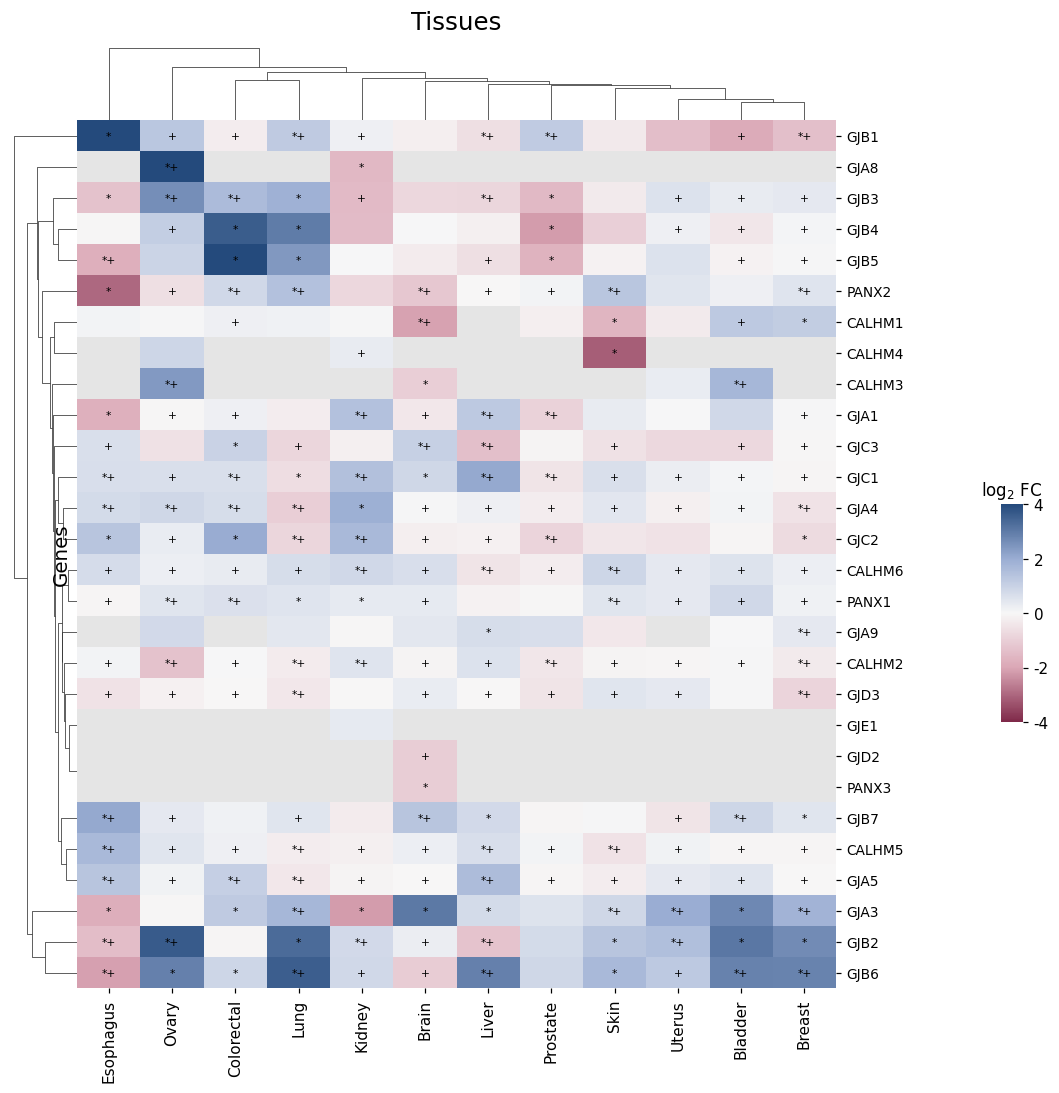

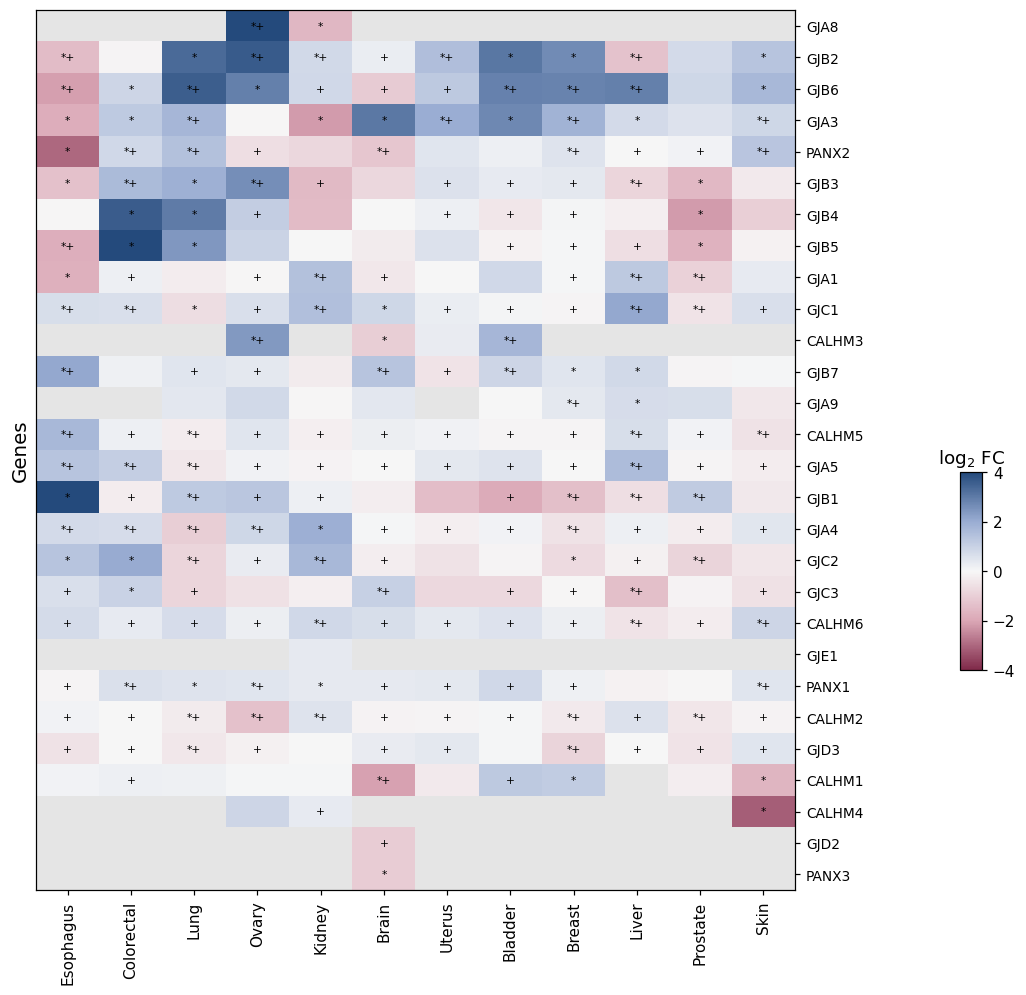

In [23]:
s3_qc=plot_expression(summary,EXPRESSION_LAYOUT,'S3_composition_adjusted_heatmap')
if EXPRESSION_LAYOUT!='uploaded_order':
    plot_expression(summary,'uploaded_order','S3_uploaded_order_heatmap')
print(s3_qc)


## 9 Reproduce Figure S4 and export evidence tables

The historical saved figure class counts are 98 concordant, 58 directionally supported/heterogeneous, and 13 method/study-sensitive. No cells in that saved figure were grey. The stricter k≥2 interpretation is provided separately and is not silently substituted for the historical one.

Historical classes and the stricter independent-study table are both saved.


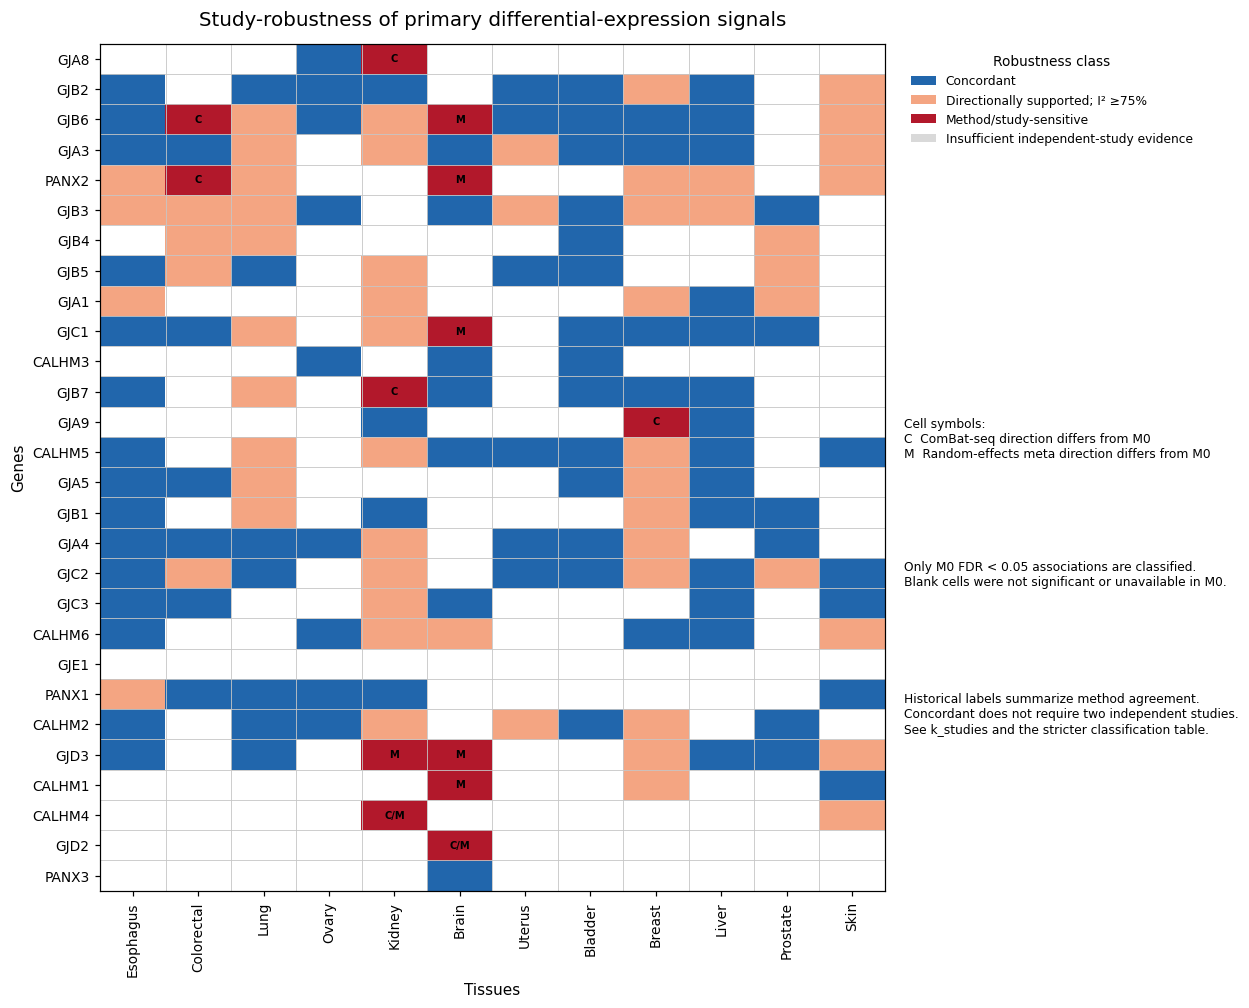

,n_associations
Robustness_class,
Concordant,98
Directionally supported; heterogeneous,58
Method/study-sensitive,13


In [24]:
s4_counts=plot_robustness(robustness)
display(s4_counts.rename('n_associations').to_frame())
strict=classify_robustness(integrated,'require_two_studies')
write_tsv(strict,OUTPUT_DIR/'tables'/'study_robustness_classification_require_two_studies.tsv')
write_tsv(robustness,OUTPUT_DIR/'tables'/'study_robustness_classification_used.tsv')
print('Historical classes and the stricter independent-study table are both saved.')


## 10 Additional checks and provenance export

Compare pooled M0 with random-effects meta-analysis and ComBat effects; review tissue composition and purity model status when running raw inputs. The version record captures the actual environment used for this notebook. Model status and missing-FDR audits are essential when a heatmap cell is blank.

Evidence availability:
Figures: S3_composition_adjusted_heatmap, S3_uploaded_order_heatmap, S4_study_robustness_heatmap (PNG/PDF).
Tables and checks: /workspace/scratch/e4c94c26dd9e/deliverables/Cancer_RNAseq_S3_S4/cancer_rnaseq_reproduced/tables


,gene_tissue_pairs
M0_significant,169
two_independent_studies,195
LOSO_available,272
ComBat_available,272


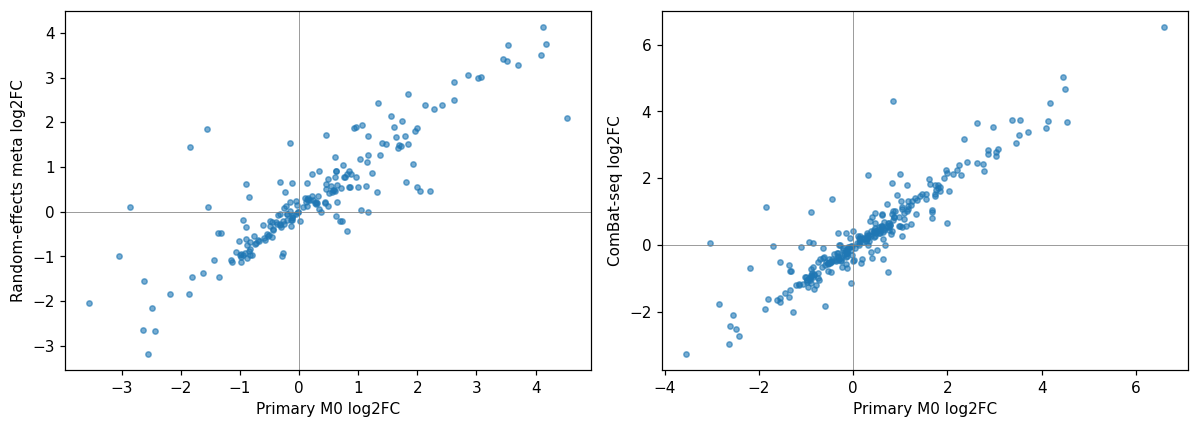

In [25]:
qc=pd.DataFrame({'M0_significant':integrated.M0_FDR.lt(ALPHA),
                 'two_independent_studies':integrated.k_studies.ge(2),
                 'LOSO_available':integrated.LOSO_direction_agreement.notna(),
                 'ComBat_available':integrated.log2FC_ComBatSeq.notna()})
print('Evidence availability:');display(qc.sum().rename('gene_tissue_pairs').to_frame())
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,col,label in zip(axes,['random_log2FC','log2FC_ComBatSeq'],['Random-effects meta','ComBat-seq']):
    good=np.isfinite(integrated.M0_log2FC)&np.isfinite(integrated[col])
    if col=='random_log2FC':good &= integrated.k_studies.ge(2)
    ax.scatter(integrated.loc[good,'M0_log2FC'],integrated.loc[good,col],s=12,alpha=.6)
    ax.axhline(0,c='grey',lw=.5);ax.axvline(0,c='grey',lw=.5)
    ax.set(xlabel='Primary M0 log2FC',ylabel=label+' log2FC')
fig.tight_layout();save_figure(fig,'M0_meta_ComBat_agreement');plt.show();plt.close(fig)
record={'mode':MODE,'layer':LAYER,'tissues':TISSUES,'targets':TARGET_GENES,
        'software':software_versions(),'archived_source_tables':SAVED_MANIFEST,
        'expression_layout':EXPRESSION_LAYOUT,'classification_mode':CLASSIFICATION_MODE,
        'raw_analysis_executed':MODE=='raw_counts','min_count':MIN_COUNT,'min_samples':MIN_SAMPLES,
        'sample_QC_exclusions':EXCLUDE_SAMPLES,'minimum_group_n':MIN_GROUP,
        'minimum_within_study_n':MIN_WITHIN,'alpha':ALPHA,'seed':RNG_SEED,
        'min_composition_complete_fraction':MIN_COMPOSITION_FRACTION,
        'max_abs_score_correlation':MAX_SCORE_CORR,'minimum_purity_tumors':MIN_PURITY_TUMORS}
(OUTPUT_DIR/'provenance'/'run_manifest.json').write_text(json.dumps(record,indent=2))
print('Figures: S3_composition_adjusted_heatmap, S3_uploaded_order_heatmap, S4_study_robustness_heatmap (PNG/PDF).')
print('Tables and checks:', (OUTPUT_DIR/'tables').resolve())


## 11 Methods references and API documentation

- Love MI, Huber W, Anders S. DESeq2. *Genome Biology* 2014. [doi:10.1186/s13059-014-0550-8](https://doi.org/10.1186/s13059-014-0550-8).
- Muzellec B et al. PyDESeq2. *Bioinformatics* 2023. [doi:10.1093/bioinformatics/btad547](https://doi.org/10.1093/bioinformatics/btad547).
- Yoshihara K et al. ESTIMATE. *Nature Communications* 2013. [doi:10.1038/ncomms3612](https://doi.org/10.1038/ncomms3612).
- Zhang Y, Parmigiani G, Johnson WE. ComBat-seq. *NAR Genomics and Bioinformatics* 2020. [doi:10.1093/nargab/lqaa078](https://doi.org/10.1093/nargab/lqaa078).
- DerSimonian R, Laird N. Meta-analysis in clinical trials. *Controlled Clinical Trials* 1986. [doi:10.1016/0197-2456(86)90046-2](https://doi.org/10.1016/0197-2456(86)90046-2).
- Higgins JPT et al. Measuring inconsistency in meta-analyses. *BMJ* 2003. [doi:10.1136/bmj.327.7414.557](https://doi.org/10.1136/bmj.327.7414.557).
- API checked against [PyDESeq2 0.5.4 DeseqDataSet](https://pydeseq2.readthedocs.io/en/v0.5.4/api/docstrings/pydeseq2.dds.DeseqDataSet.html) and [DeseqStats](https://pydeseq2.readthedocs.io/en/v0.5.4/api/docstrings/pydeseq2.ds.DeseqStats.html). Explicit design matrices require numeric contrasts; this is used for the continuous purity effect.

